# DemandIQ: Exploratory Data Analysis
    {
     "cell_type": "markdown",
     "id": "f5b9607c",
     "metadata": {"language": "markdown"},

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'data' / 'raw' / 'rossmann').is_dir())
data_dir = project_root / 'data' / 'raw' / 'rossmann'
train = pd.read_csv(data_dir / 'train.csv', low_memory=False)
test = pd.read_csv(data_dir / 'test.csv', low_memory=False)
store = pd.read_csv(data_dir / 'store.csv', low_memory=False)
train_eda = train.assign(Date=pd.to_datetime(train['Date']))
train_eda['Year'] = train_eda['Date'].dt.year
train_eda['Month'] = train_eda['Date'].dt.month
train_eda['MonthName'] = train_eda['Date'].dt.strftime('%b')
train_eda['DayName'] = train_eda['Date'].dt.day_name()

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)
print(f'Loaded {len(train_eda):,} historical observations for EDA.')

Loaded 1,017,209 historical observations for EDA.


## 1. EDA Objective

The goal is to understand how sales vary across demand intensity, time, stores, promotions, holidays, customers, opening status, and competition. These observations will identify later preparation needs and plausible modeling inputs, while respecting what is actually available at forecast time.

## 2. Sales Distribution

Sales are examined on the original scale and among open stores. The open-store view separates the structural mass of closure-related zeros from demand levels when a store is operating. High values are investigated with percentiles and context rather than automatically labeled as errors.

Sales percentiles


,Sales
0.000,0.000
0.010,0.000
0.250,3727.000
0.500,5744.000
0.750,7856.000
0.950,12137.000
0.990,17160.000
0.999,23979.792
1.000,41551.000


Overall skewness: 0.641
Open-store skewness: 1.594


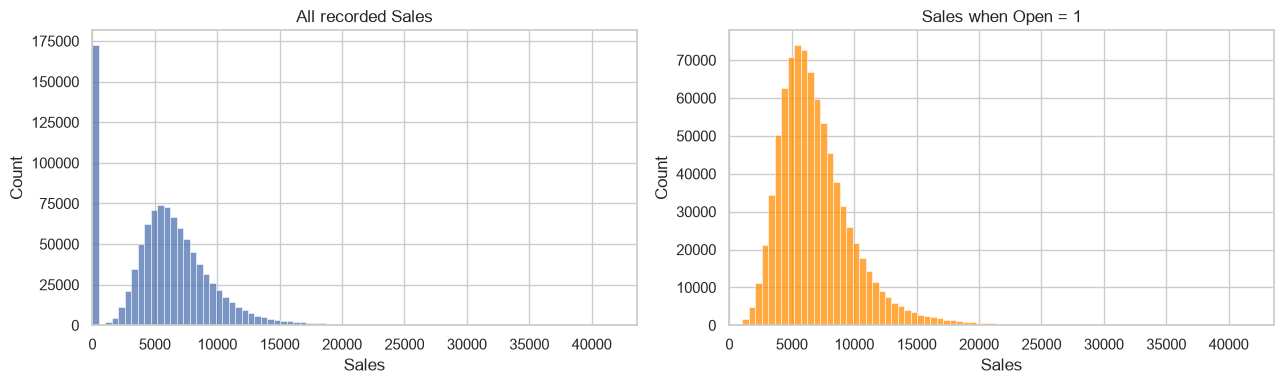

In [2]:
open_sales = train_eda.loc[train_eda['Open'].eq(1), 'Sales']
percentiles = train_eda['Sales'].quantile([0, .01, .25, .5, .75, .95, .99, .999, 1]).rename('Sales')
print('Sales percentiles')
display(percentiles.to_frame())
print(f'Overall skewness: {train_eda.Sales.skew():.3f}')
print(f'Open-store skewness: {open_sales.skew():.3f}')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train_eda['Sales'], bins=80, ax=axes[0])
axes[0].set_title('All recorded Sales')
axes[0].set_xlim(left=0)
sns.histplot(open_sales, bins=80, ax=axes[1], color='darkorange')
axes[1].set_title('Sales when Open = 1')
axes[1].set_xlim(left=0)
plt.tight_layout()
plt.show()

In [3]:
top_sales = train_eda.nlargest(10, 'Sales')[['Store', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']]
print('Ten highest sales observations with operational context')
display(top_sales)
print('Interpretation: extreme values occur in specific store-date contexts and should be investigated later. A large value is not, by itself, evidence of a data error or an outlier to remove.')

Ten highest sales observations with operational context


,Store,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
44393,909,2015-06-22,41551,1721,1,0,0,0
132946,262,2015-04-03,38722,5132,1,1,b,0
101726,262,2015-05-01,38484,5458,1,1,a,0
87231,262,2015-05-14,38367,5192,1,0,a,1
424086,57,2014-06-16,38037,1970,1,1,0,0
627776,817,2013-12-16,38025,4381,1,1,0,0
627220,261,2013-12-16,37646,1964,1,1,0,0
444361,262,2014-05-29,37403,5297,1,0,a,0
620531,262,2013-12-22,37376,4916,1,0,0,0
245945,262,2014-12-21,37122,4962,1,0,0,0


Interpretation: extreme values occur in specific store-date contexts and should be investigated later. A large value is not, by itself, evidence of a data error or an outlier to remove.


## 3. Temporal Demand Patterns

Aggregated means and medians show how typical demand differs by weekday, calendar month, and year. The time-series view uses monthly averages to reveal longer-term evolution without constructing lag or rolling features.

,count,mean,median
DayName,,,
Monday,144730,"7,809","7,310"
Tuesday,145664,"7,005","6,463"
Wednesday,145665,"6,556","6,133"
Thursday,145845,"6,248","6,020"
Friday,145845,"6,723","6,434"
Saturday,144730,"5,848","5,410"
Sunday,144730,204,0


,count,mean,median
Month,,,
1,103694,"5,465","5,483"
2,93660,"5,645","5,610"
3,103695,"5,785","5,750"
4,100350,"5,739","5,718"
5,103695,"5,490","5,717"
6,100350,"5,761","5,729"
7,98115,"6,065","5,953"
8,63550,"5,693","5,633"
9,61500,"5,570","5,504"


,count,mean,median
Year,,,
2013,406974,"5,659","5,598"
2014,373855,"5,833","5,794"
2015,236380,"5,878","5,916"


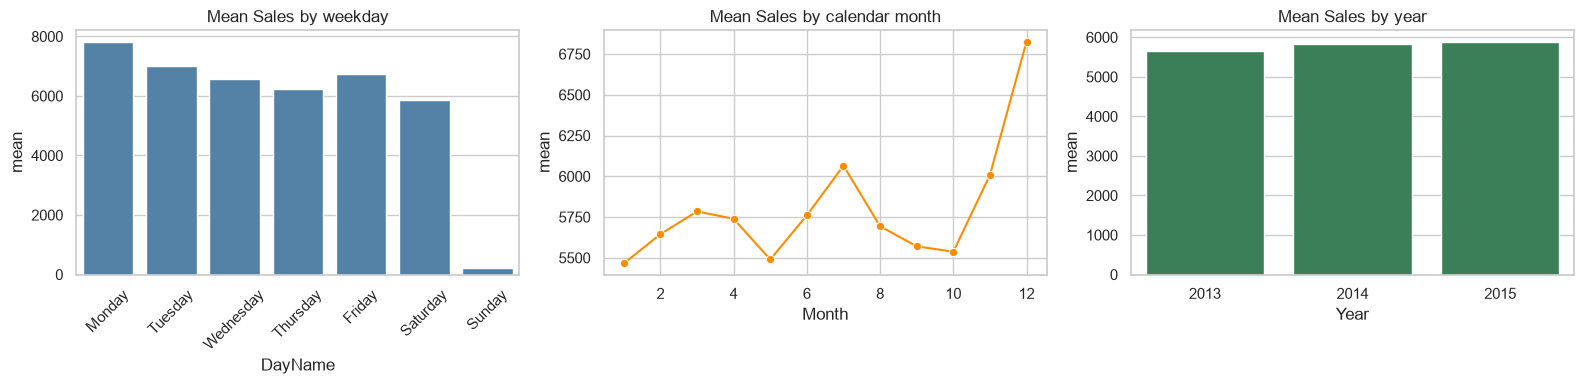

In [4]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
month_order = list(range(1, 13))
day_summary = train_eda.groupby('DayName', observed=True)['Sales'].agg(['count', 'mean', 'median']).reindex(day_order)
month_summary = train_eda.groupby('Month', observed=True)['Sales'].agg(['count', 'mean', 'median']).reindex(month_order)
year_summary = train_eda.groupby('Year', observed=True)['Sales'].agg(['count', 'mean', 'median'])
display(day_summary.style.format({'mean':'{:,.0f}', 'median':'{:,.0f}'}))
display(month_summary.style.format({'mean':'{:,.0f}', 'median':'{:,.0f}'}))
display(year_summary.style.format({'mean':'{:,.0f}', 'median':'{:,.0f}'}))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=day_summary.reset_index(), x='DayName', y='mean', ax=axes[0], color='steelblue')
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_title('Mean Sales by weekday')
sns.lineplot(data=month_summary.reset_index(), x='Month', y='mean', marker='o', ax=axes[1], color='darkorange')
axes[1].set_title('Mean Sales by calendar month')
sns.barplot(data=year_summary.reset_index(), x='Year', y='mean', ax=axes[2], color='seagreen')
axes[2].set_title('Mean Sales by year')
plt.tight_layout()
plt.show()

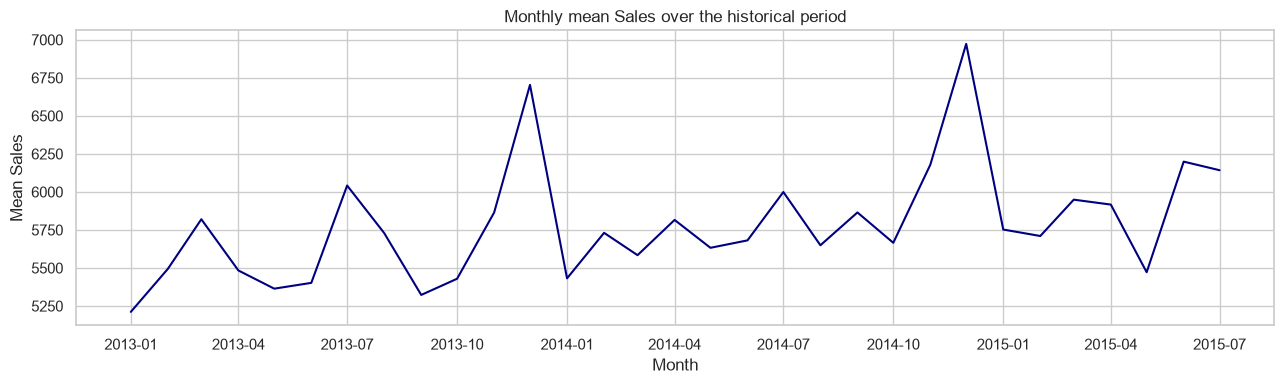

Interpretation: calendar position and longer-term time period are visibly relevant descriptors, but this plot alone does not establish why demand changes.


In [5]:
monthly_sales = train_eda.set_index('Date')['Sales'].resample('MS').mean()
plt.figure(figsize=(13, 4))
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, color='navy')
plt.title('Monthly mean Sales over the historical period')
plt.xlabel('Month')
plt.ylabel('Mean Sales')
plt.tight_layout()
plt.show()
print('Interpretation: calendar position and longer-term time period are visibly relevant descriptors, but this plot alone does not establish why demand changes.')

## 4. Store Heterogeneity

Stores differ in their typical demand and spread. Store-level distributions are summarized with quantiles, then compared by the store dimension attributes `StoreType` and `Assortment`. These comparisons describe heterogeneous operating contexts; they do not rank stores as inherently better or worse.

Store-level sales distribution across stores


,mean,median,std,min,max
count,1115.0,1115.0,1115.0,1115.0,1115.0
mean,5763.3,6209.2,3096.1,50.9,15368.4
std,2046.4,2217.4,993.3,610.0,5357.5
min,2244.5,2028.5,1276.8,0.0,5759.0
25%,4412.4,4711.5,2417.5,0.0,11700.0
50%,5459.2,5843.0,2965.2,0.0,14531.0
75%,6633.9,7135.8,3565.5,0.0,17944.0
max,20718.5,20914.0,9183.5,13210.0,41551.0


Store-level typical demand by StoreType


,stores,mean_sales,median_sales
StoreType,,,
a,602,5727.0,6171.6
b,17,10005.5,9758.7
c,148,5709.5,6183.5
d,348,5641.8,6111.8


Store-level typical demand by Assortment


,stores,mean_sales,median_sales
Assortment,,,
a,593,5468.5,5879.2
b,9,8485.8,8326.1
c,513,6056.4,6553.6


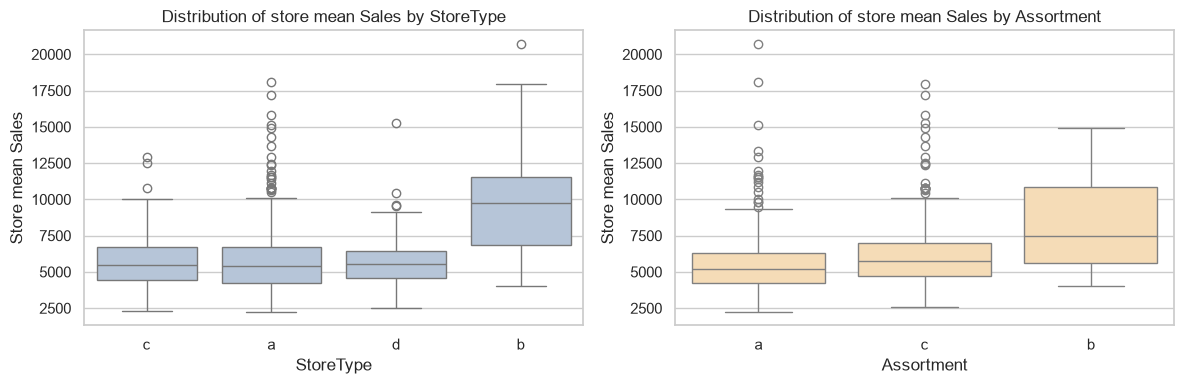

In [6]:
store_sales = train_eda.groupby('Store')['Sales'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print('Store-level sales distribution across stores')
display(store_sales[['mean', 'median', 'std', 'min', 'max']].describe().round(1))
store_eda = store.merge(store_sales[['mean', 'median']], left_on='Store', right_index=True, how='left')
type_summary = store_eda.groupby('StoreType', observed=True).agg(stores=('Store','size'), mean_sales=('mean','mean'), median_sales=('median','mean')).sort_index()
assortment_summary = store_eda.groupby('Assortment', observed=True).agg(stores=('Store','size'), mean_sales=('mean','mean'), median_sales=('median','mean')).sort_index()
print('Store-level typical demand by StoreType')
display(type_summary.round(1))
print('Store-level typical demand by Assortment')
display(assortment_summary.round(1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=store_eda, x='StoreType', y='mean', ax=axes[0], color='lightsteelblue')
axes[0].set_title('Distribution of store mean Sales by StoreType')
axes[0].set_ylabel('Store mean Sales')
sns.boxplot(data=store_eda, x='Assortment', y='mean', ax=axes[1], color='navajowhite')
axes[1].set_title('Distribution of store mean Sales by Assortment')
axes[1].set_ylabel('Store mean Sales')
plt.tight_layout()
plt.show()

## 5. Promotion Effects

The tables below compare observed sales on `Promo` days and non-promo days, and separately describe `Promo2` store coverage. These are observational differences: they are not estimates of a causal promotion effect and may reflect different dates, stores, or operating conditions.

,count,mean,median
Promo,,,
0,629129,"4,406","4,622"
1,388080,"7,991","7,553"


,count
Promo2,
0,544
1,571


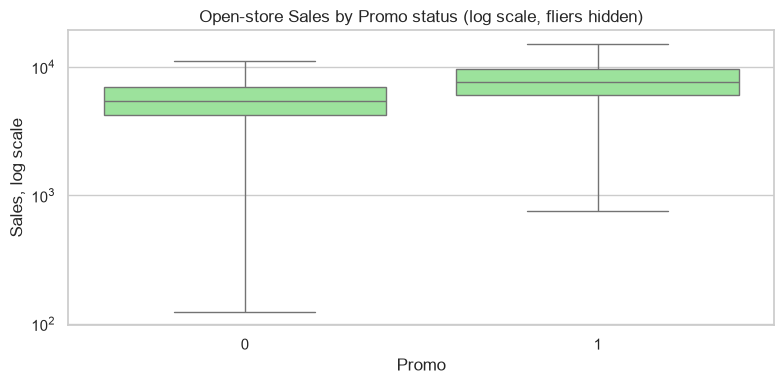

Interpretation: Promo groups have different observed demand levels. The open-store comparison reduces one structural difference, but it still does not control for store, date, or other conditions.


In [7]:
promo_summary = train_eda.groupby('Promo', observed=True)['Sales'].agg(['count', 'mean', 'median'])
display(promo_summary.style.format({'mean':'{:,.0f}', 'median':'{:,.0f}'}))
promo_by_open = train_eda.groupby(['Open', 'Promo'], observed=True)['Sales'].agg(['count', 'mean', 'median'])
display(promo_by_open.style.format({'mean':'{:,.0f}', 'median':'{:,.0f}'}))
promo_store_summary = store.groupby('Promo2', observed=True)['Store'].agg(['count'])
display(promo_store_summary)
plt.figure(figsize=(8, 4))
sns.boxplot(data=train_eda.loc[train_eda['Open'].eq(1)], x='Promo', y='Sales', showfliers=False, color='lightgreen')
plt.yscale('log')
plt.title('Open-store Sales by Promo status (log scale, fliers hidden)')
plt.ylabel('Sales, log scale')
plt.tight_layout()
plt.show()
print('Interpretation: Promo groups have different observed demand levels. The open-store comparison reduces one structural difference, but it still does not control for store, date, or other conditions.')

## 6. Holiday Effects

State holidays and school holidays are compared with counts, means, and medians. State-holiday groups include many closed observations, so open-store context is shown where it makes the comparison more interpretable.

StateHoliday summary


,count,mean,median
StateHoliday,,,
0,986159,"5,947","5,849"
a,20260,291,0
b,6690,214,0
c,4100,169,0


SchoolHoliday summary


,count,mean,median
SchoolHoliday,,,
0,835488,"5,621","5,642"
1,181721,"6,477","6,197"


StateHoliday among open stores


,count,mean,median
StateHoliday,,,
0,843482,"6,954","6,368"
a,694,"8,487","7,556"
b,145,"9,888","8,423"
c,71,"9,744","8,397"


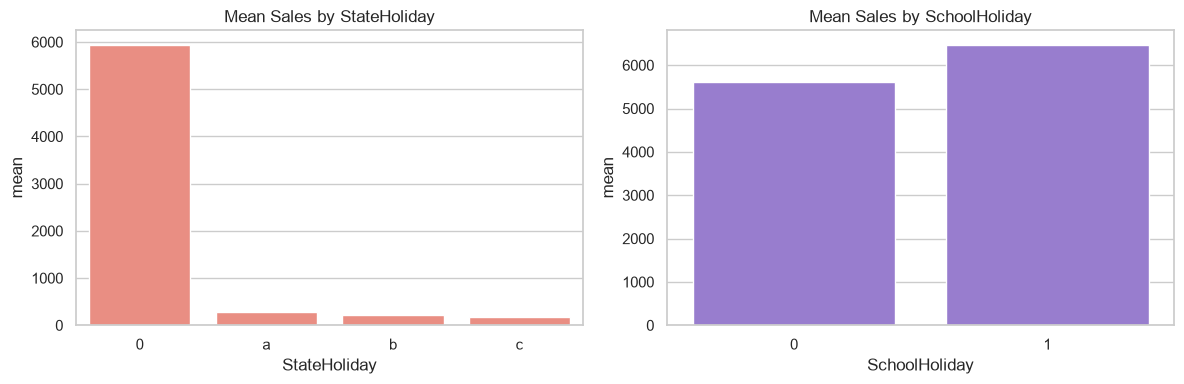

Interpretation: holiday categories differ in observed demand and operating composition. No causal holiday effect is inferred.


In [8]:
holiday_summary = train_eda.groupby('StateHoliday', dropna=False, observed=True)['Sales'].agg(['count', 'mean', 'median'])
school_summary = train_eda.groupby('SchoolHoliday', observed=True)['Sales'].agg(['count', 'mean', 'median'])
print('StateHoliday summary')
display(holiday_summary.style.format({'mean':'{:,.0f}', 'median':'{:,.0f}'}))
print('SchoolHoliday summary')
display(school_summary.style.format({'mean':'{:,.0f}', 'median':'{:,.0f}'}))
state_open = train_eda.loc[train_eda['Open'].eq(1)].groupby('StateHoliday', observed=True)['Sales'].agg(['count','mean','median'])
print('StateHoliday among open stores')
display(state_open.style.format({'mean':'{:,.0f}', 'median':'{:,.0f}'}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=holiday_summary.reset_index(), x='StateHoliday', y='mean', ax=axes[0], color='salmon')
axes[0].set_title('Mean Sales by StateHoliday')
sns.barplot(data=school_summary.reset_index(), x='SchoolHoliday', y='mean', ax=axes[1], color='mediumpurple')
axes[1].set_title('Mean Sales by SchoolHoliday')
plt.tight_layout()
plt.show()
print('Interpretation: holiday categories differ in observed demand and operating composition. No causal holiday effect is inferred.')

## 7. Customers and Sales

Customers and Sales show a strong historical relationship in the training data. This is useful for understanding observed demand, but `Customers` is not available in `test`; using future customer counts directly in a final forecast would violate prediction-time availability and create leakage.

Historical Pearson correlation between Customers and Sales: 0.895


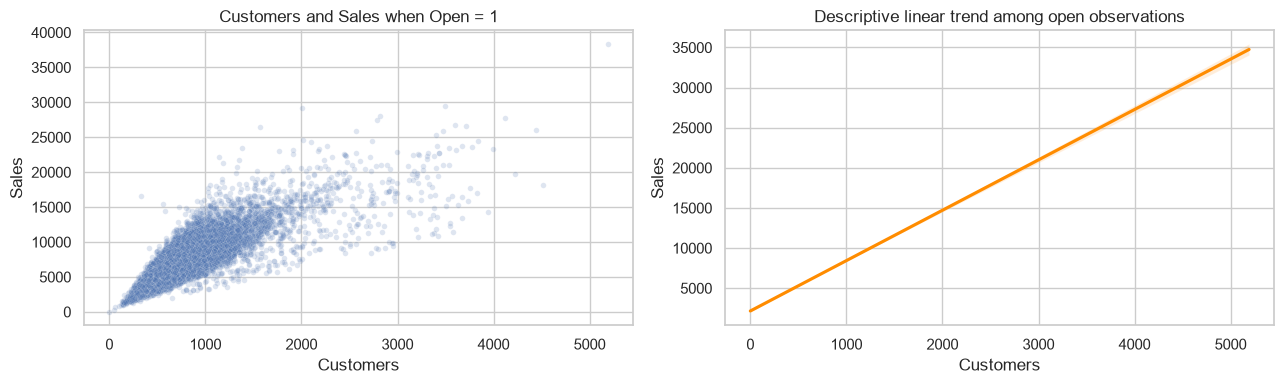

Modeling constraint: Customers may support historical diagnostics, but it must not become a final future prediction feature because it is absent from test.


In [9]:
customer_sales_corr = train_eda[['Customers', 'Sales']].corr().loc['Customers', 'Sales']
print(f'Historical Pearson correlation between Customers and Sales: {customer_sales_corr:.3f}')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sample_for_plot = train_eda.sample(n=min(20000, len(train_eda)), random_state=42)
sns.scatterplot(data=sample_for_plot.loc[sample_for_plot['Open'].eq(1)], x='Customers', y='Sales', alpha=.18, s=16, ax=axes[0])
axes[0].set_title('Customers and Sales when Open = 1')
sns.regplot(data=sample_for_plot.loc[sample_for_plot['Open'].eq(1)], x='Customers', y='Sales', scatter=False, ax=axes[1], color='darkorange')
axes[1].set_title('Descriptive linear trend among open observations')
plt.tight_layout()
plt.show()
print('Modeling constraint: Customers may support historical diagnostics, but it must not become a final future prediction feature because it is absent from test.')

## 8. Open / Closed Behavior

Closure is a structural part of the data. Sales are expected to be zero for nearly all closed observations, so zeros should not automatically be treated as demand anomalies. The few exceptions are reported for later investigation rather than changed.

In [10]:
open_summary = train_eda.groupby('Open', observed=True)['Sales'].agg(['count', 'mean', 'median', 'min', 'max'])
display(open_summary)
closed_nonzero = train_eda.loc[train_eda['Open'].eq(0) & train_eda['Sales'].ne(0)]
open_zero = train_eda.loc[train_eda['Open'].eq(1) & train_eda['Sales'].eq(0)]
print(f'Closed observations with non-zero Sales: {len(closed_nonzero):,}')
print(f'Open observations with zero Sales: {len(open_zero):,}')
if not closed_nonzero.empty:
    display(closed_nonzero[['Store','Date','Sales','Open','StateHoliday','Promo']].head(10))
print('Interpretation: the dominant zero-sales pattern is tied to closure status. Exceptions are data-quality questions for later work, not rows to delete during EDA.')

,count,mean,median,min,max
Open,,,,,
0,172817,0.000000,0.0,0,0
1,844392,6955.514291,6369.0,0,41551


Closed observations with non-zero Sales: 0
Open observations with zero Sales: 54
Interpretation: the dominant zero-sales pattern is tied to closure status. Exceptions are data-quality questions for later work, not rows to delete during EDA.


## 9. Competition

Competition distance is a store-level attribute. Its relationship with typical store sales is summarized by distance bands and a scatter plot. This is descriptive association only; distance is entangled with store context and does not establish a competitive causal effect.

,stores,mean_store_sales,median_store_sales
DistanceBand,,,
"(19.999, 520.0]",226,6269.6,6709.3
"(520.0, 1600.0]",221,5694.4,6134.6
"(1600.0, 3450.0]",221,5562.1,6022.3
"(3450.0, 8666.0]",221,5621.2,6099.5
"(8666.0, 75860.0]",223,5676.5,6089.7


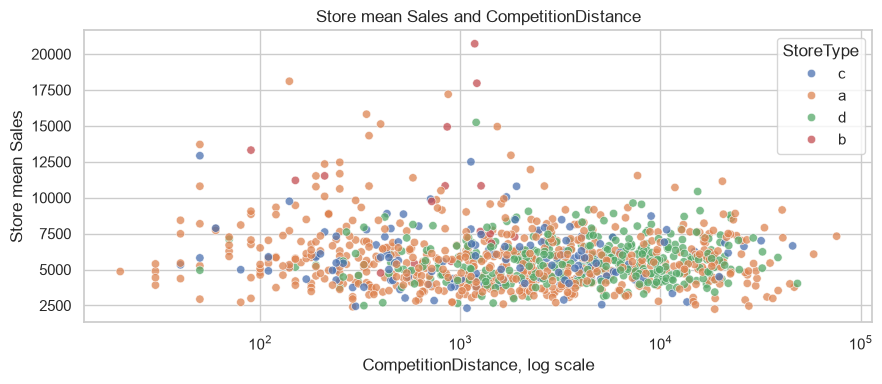

Interpretation: distance bands and store means may differ, but the grouped relationship is not a causal estimate and should be interpreted with store attributes and time in mind.


In [11]:
store_eda['DistanceBand'] = pd.qcut(store_eda['CompetitionDistance'], q=5, duplicates='drop')
distance_summary = store_eda.groupby('DistanceBand', observed=True).agg(stores=('Store','size'), mean_store_sales=('mean','mean'), median_store_sales=('median','mean'))
display(distance_summary.round(1))
plt.figure(figsize=(9, 4))
sns.scatterplot(data=store_eda, x='CompetitionDistance', y='mean', hue='StoreType', alpha=.75)
plt.xscale('log')
plt.title('Store mean Sales and CompetitionDistance')
plt.xlabel('CompetitionDistance, log scale')
plt.ylabel('Store mean Sales')
plt.tight_layout()
plt.show()
print('Interpretation: distance bands and store means may differ, but the grouped relationship is not a causal estimate and should be interpreted with store attributes and time in mind.')

## 10. Anomalies

Potential anomalies are assessed through zero behavior, high-sales percentiles, and temporal/store context. No observation is removed. Extreme values may represent legitimate high-demand days, promotions, large stores, or holiday effects; they require domain review before any later treatment.

In [12]:
high_threshold = train_eda['Sales'].quantile(.99)
high_sales = train_eda.loc[train_eda['Sales'] >= high_threshold]
anomaly_context = high_sales.groupby(['Promo', 'Open'], observed=True).agg(observations=('Sales','size'), mean_sales=('Sales','mean'), median_customers=('Customers','median'))
print(f'99th percentile threshold: {high_threshold:,.0f}; observations at or above it: {len(high_sales):,}')
display(anomaly_context.round(1))
print('Highest-demand dates among the 99th-percentile observations')
display(high_sales.groupby('Date', observed=True)['Sales'].agg(['count','mean','max']).nlargest(10, 'max'))
print('Assessment: high observations have business context available for inspection. They are not automatically errors or candidates for deletion.')

99th percentile threshold: 17,160; observations at or above it: 10,178


,,observations,mean_sales,median_customers
Promo,Open,,,
0,1,2886,20214.8,2807.0
1,1,7292,20245.4,2192.5


Highest-demand dates among the 99th-percentile observations


,count,mean,max
Date,,,
2015-06-22,4,24999.750000,41551
2015-04-03,5,23372.400000,38722
2015-05-01,4,25530.250000,38484
2015-05-14,5,22876.800000,38367
2014-06-16,33,20604.878788,38037
2013-12-16,251,21271.561753,38025
2014-05-29,3,26679.333333,37403
2013-12-22,3,27895.666667,37376
2014-12-21,3,27548.000000,37122


Assessment: high observations have business context available for inspection. They are not automatically errors or candidates for deletion.


## 11. Relationships and Multivariate Insights

A small set of numeric relationships is examined where correlation is meaningful: Sales, Customers, Promo, Open, SchoolHoliday, and CompetitionDistance after joining store attributes. This is not a blanket correlation exercise, and correlations do not establish causation.

,Sales,Customers,Promo,Open,SchoolHoliday,CompetitionDistance,Promo2
Sales,1.00,0.89,0.45,0.68,0.09,-0.02,-0.09
Customers,0.89,1.00,0.32,0.62,0.07,-0.10,-0.15
Promo,0.45,0.32,1.00,0.30,0.07,0.00,-0.00
Open,0.68,0.62,0.30,1.00,0.09,0.01,-0.01
SchoolHoliday,0.09,0.07,0.07,0.09,1.00,-0.00,-0.01
CompetitionDistance,-0.02,-0.10,0.00,0.01,-0.00,1.00,-0.14
Promo2,-0.09,-0.15,-0.00,-0.01,-0.01,-0.14,1.00


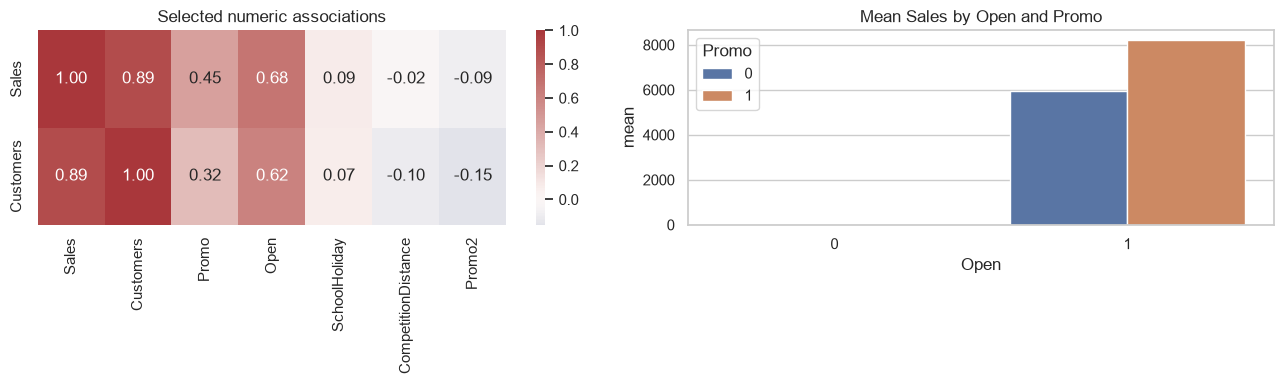

Interpretation: Sales aligns strongly with historical Customers and differs across operating states, but these associations must be validated with time-aware methods and prediction-time availability later.


In [13]:
analysis_frame = train_eda.merge(store[['Store', 'CompetitionDistance', 'Promo2']], on='Store', how='left')
numeric_columns = ['Sales', 'Customers', 'Promo', 'Open', 'SchoolHoliday', 'CompetitionDistance', 'Promo2']
correlation = analysis_frame[numeric_columns].corr()
display(correlation.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(correlation.loc[['Sales','Customers'], ['Sales','Customers','Promo','Open','SchoolHoliday','CompetitionDistance','Promo2']], annot=True, fmt='.2f', cmap='vlag', center=0, ax=axes[0])
axes[0].set_title('Selected numeric associations')
grouped_context = analysis_frame.groupby(['Open','Promo'], observed=True)['Sales'].agg(['count','mean','median']).reset_index()
sns.barplot(data=grouped_context, x='Open', y='mean', hue='Promo', ax=axes[1])
axes[1].set_title('Mean Sales by Open and Promo')
plt.tight_layout()
plt.show()
print('Interpretation: Sales aligns strongly with historical Customers and differs across operating states, but these associations must be validated with time-aware methods and prediction-time availability later.')

## 12. EDA Conclusions

### A. Major demand patterns
- Sales are right-skewed, with a large structural zero mass associated with closed stores and a long upper tail among demand observations.
- Typical demand differs across weekday, month, year, and store, indicating substantial temporal and cross-store heterogeneity.

### B. Important store differences
- Store-level mean and median sales vary materially. StoreType and Assortment groups show different distributions of typical store demand, so store identity and store attributes may matter later.

### C. Promotion and holiday observations
- Promo and non-promo observations have different descriptive sales levels, but the comparison is observational and does not establish a causal lift.
- StateHoliday and SchoolHoliday groups differ in demand and closure composition; open status must be considered when interpreting holiday tables.

### D. Important temporal behavior
- The historical period contains weekday, monthly, yearly, and longer-term changes. Chronological ordering should therefore remain central to later validation.

### E. Potential anomalies
- Very high sales and open-zero or closed-nonzero records warrant contextual review. High demand may be legitimate business behavior, and no outliers were removed here.

### F. Variables that appear useful later
- Date-derived calendar information, Store, store attributes, Open, scheduled promotion fields, and holiday fields are plausible candidates subject to availability and validation checks.

### G. Leakage or availability problems
- Sales is the target and cannot be used as an input. Customers is strongly associated with historical Sales but is absent from test, so it must not be a final future feature. Any post-forecast measurement or future outcome would create leakage.

### H. Implications for feature engineering
- Later preparation should define time-aware validation, preserve forecast-time information boundaries, document treatment of missing values, and represent calendar/store/promotion context without silently changing raw data.

This notebook performed EDA only. It did not create lag or rolling features, split data, select features, train models, clean rows, impute values, or write processed datasets.